# 04 — Model evaluation

This notebook reports held-out test performance, parity plots, residual error,
and permutation feature importance for the best model of each target.

Best models are selected by **validation R²**, not by test R². Test metrics are
reported only after selection. For `Ioff` and `SS`, the polynomial model has a
slightly higher test R² than the selected ANN, which is useful to report as a
model-selection sensitivity.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent
METRICS = PROJECT / "results" / "metrics"
PREDS = PROJECT / "results" / "predictions"
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

m = pd.read_csv(METRICS / "model_comparison.csv")
best = pd.read_csv(METRICS / "best_models.csv")
fi = pd.read_csv(METRICS / "feature_importance.csv")

print("Best FoM models (validation-selected)")
display(best[best.task == "fom"][["target", "model", "val_r2", "test_r2", "test_mae", "test_rmse"]].round(4))
print("Best curve model")
display(best[best.task == "curve"][["target", "model", "val_r2", "test_r2", "test_mae", "test_rmse"]].round(4))

Best FoM models (validation-selected)


,target,model,val_r2,test_r2,test_mae,test_rmse
1,SS_min_mV_per_dec,ann,0.9703,0.9461,3.1471,4.8669
2,Vth_V,ann,0.9076,0.8753,0.0564,0.1067
3,log10_Ioff,ann,0.9925,0.9964,0.0279,0.0387
4,log10_Ion,polynomial,0.9891,0.9935,0.0530,0.0737
5,log10_gm_max,polynomial,0.9889,0.9950,0.0418,0.0557


Best curve model


,target,model,val_r2,test_r2,test_mae,test_rmse
0,log10_Id,ann,0.9993,0.9993,0.0569,0.082


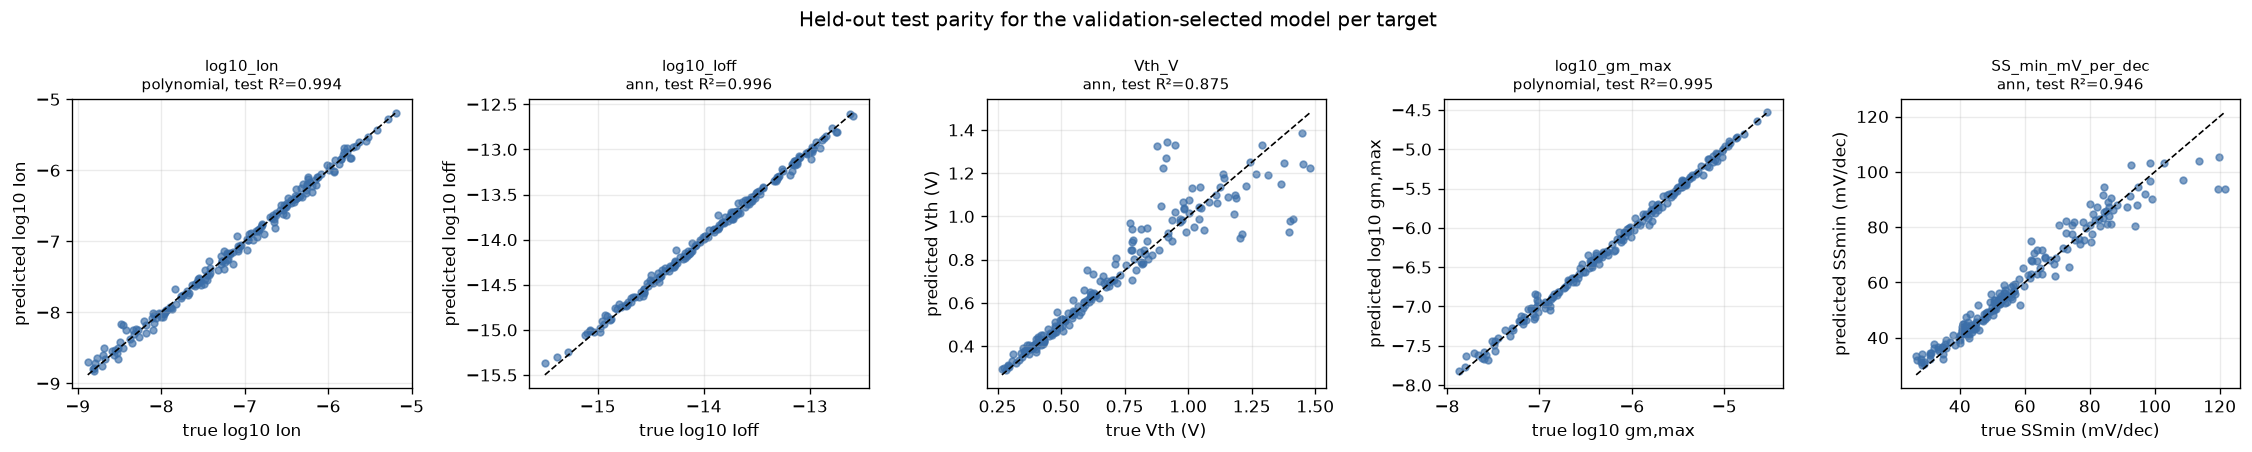

In [2]:
targets = ["log10_Ion", "log10_Ioff", "Vth_V", "log10_gm_max", "SS_min_mV_per_dec"]
labels = ["log10 Ion", "log10 Ioff", "Vth (V)", "log10 gm,max", "SSmin (mV/dec)"]
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, target, label in zip(axes, targets, labels):
    r = best[(best.task == "fom") & (best.target == target)].iloc[0]
    p = pd.read_csv(PREDS / f"fom_{target}_{r.model}.csv")
    p = p[p.split == "test"]
    ax.scatter(p.y_true, p.y_pred, s=16, alpha=0.65, color="#3b6ea8")
    lo = min(p.y_true.min(), p.y_pred.min())
    hi = max(p.y_true.max(), p.y_pred.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_xlabel(f"true {label}")
    ax.set_ylabel(f"predicted {label}")
    ax.set_title(f"{target}\n{r.model}, test R²={r.test_r2:.3f}", fontsize=9)
fig.suptitle("Held-out test parity for the validation-selected model per target")
fig.tight_layout()
plt.show()

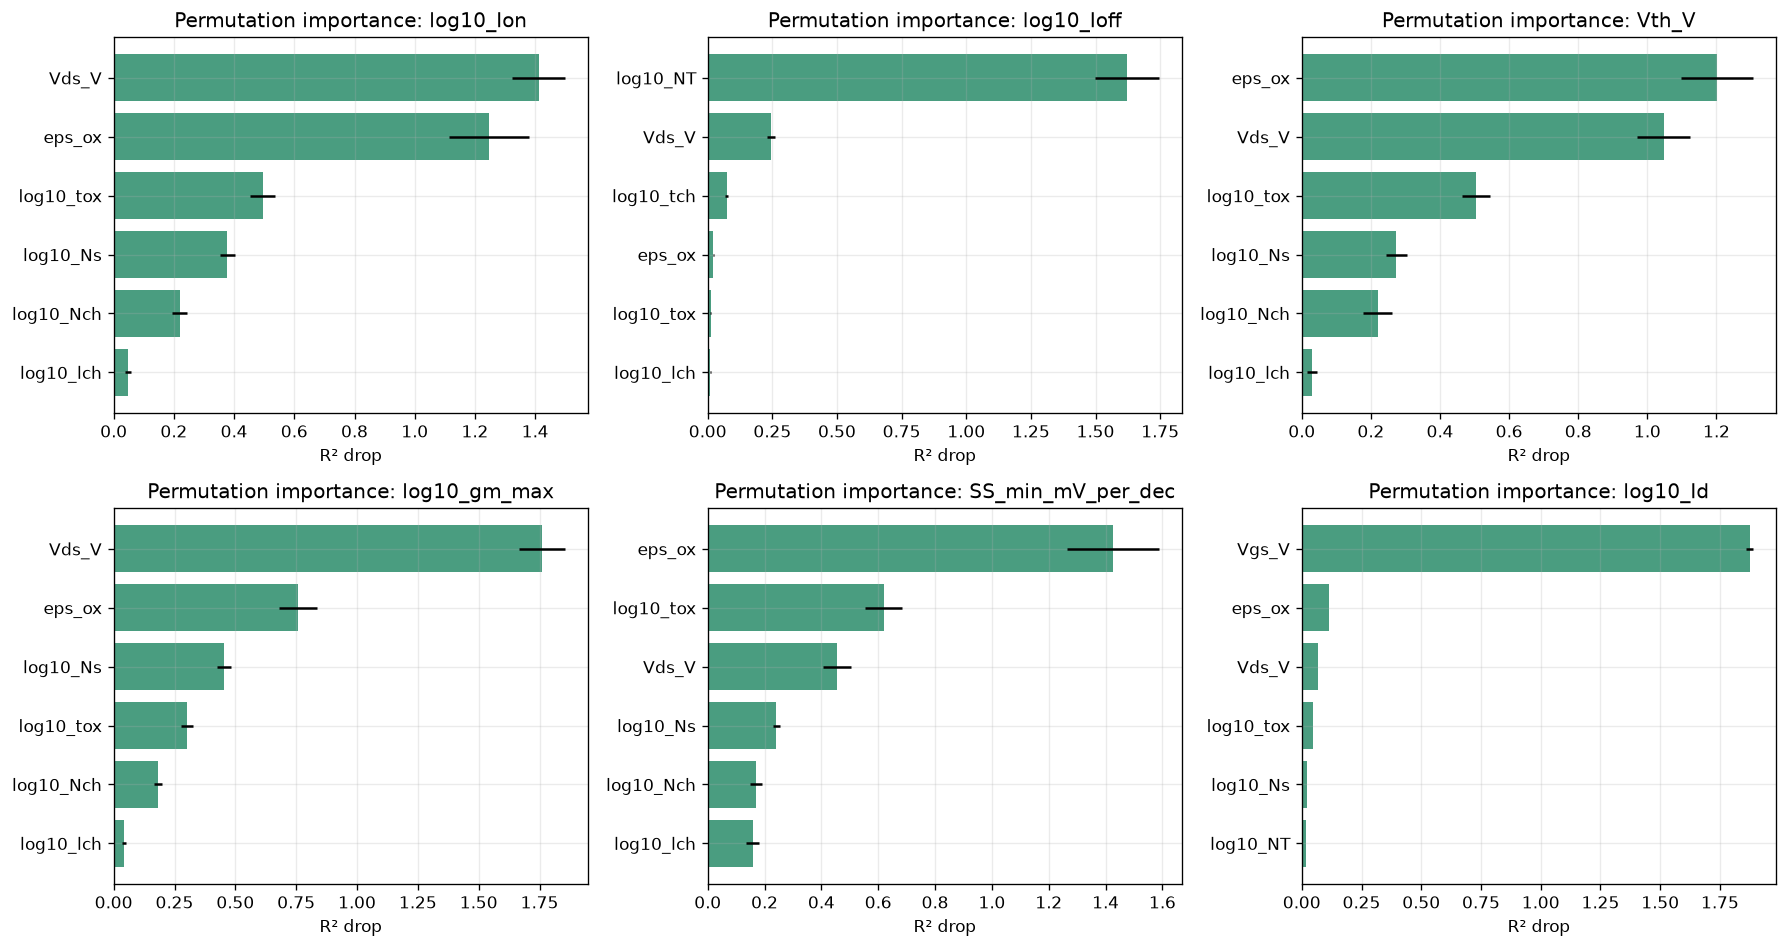

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, target in zip(axes.ravel(), targets + ["log10_Id"]):
    g = fi[fi.target == target].sort_values("importance_mean", ascending=False).head(6)
    if len(g) == 0:
        ax.axis("off")
        continue
    ax.barh(g.feature[::-1], g.importance_mean[::-1], xerr=g.importance_std[::-1], color="#2a8c6a", alpha=0.85)
    ax.set_title(f"Permutation importance: {target}")
    ax.set_xlabel("R² drop")
for ax in axes.ravel()[len(targets) + 1:]:
    ax.axis("off")
fig.tight_layout()
plt.show()

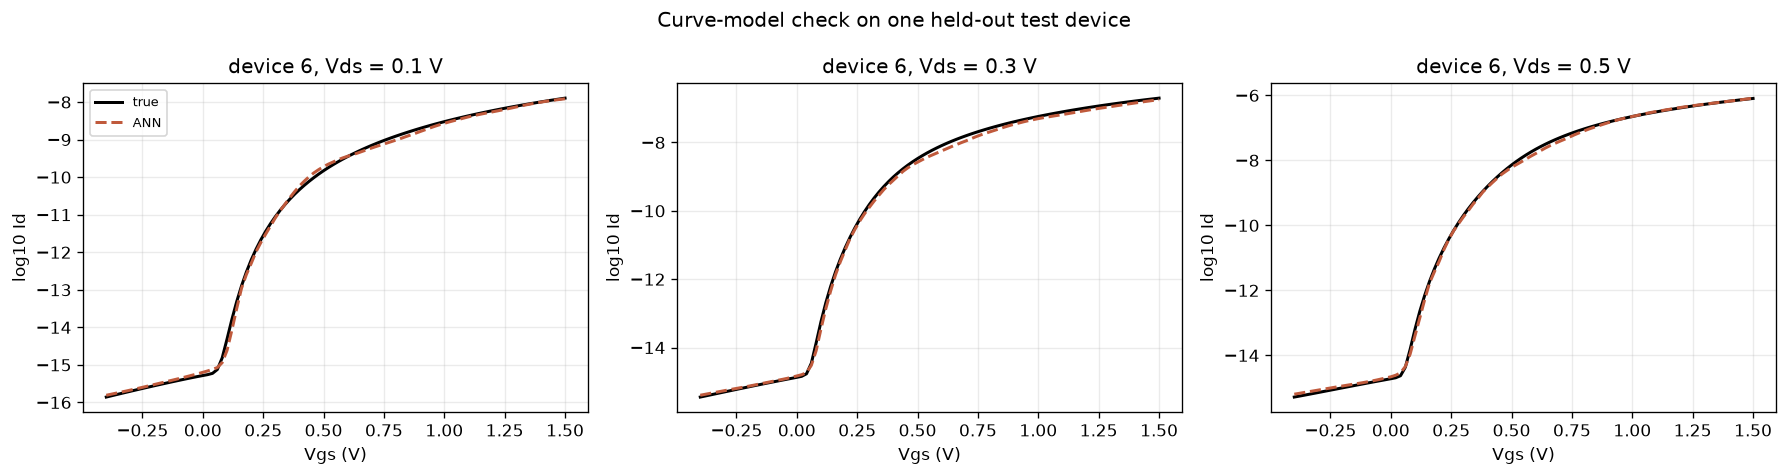

curve test residuals: mean 0.0137, std 0.0809, MAE 0.0569


In [4]:
cp = pd.read_csv(PREDS / "curve_log10_Id_ann.csv")
test = cp[cp.split == "test"]
dev = int(test.device_id.iloc[0])
g = test[test.device_id == dev].sort_values(["Vds_V", "Vgs_V"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, vd in zip(axes, [0.1, 0.3, 0.5]):
    h = g[g.Vds_V == vd]
    ax.plot(h.Vgs_V, h.y_true, "k-", lw=1.8, label="true")
    ax.plot(h.Vgs_V, h.y_pred, "--", color="#c05a3c", lw=1.8, label="ANN")
    ax.set_xlabel("Vgs (V)")
    ax.set_ylabel("log10 Id")
    ax.set_title(f"device {dev}, Vds = {vd} V")
axes[0].legend(fontsize=8)
fig.suptitle("Curve-model check on one held-out test device")
fig.tight_layout()
plt.show()

err = (cp[cp.split == "test"].y_pred - cp[cp.split == "test"].y_true)
print("curve test residuals: mean %.4f, std %.4f, MAE %.4f" % (err.mean(), err.std(), err.abs().mean()))

### Reading the results

- `log10 Ion` and `log10 gm,max` are best modelled by the polynomial ridge model.
- `log10 Ioff`, `Vth`, and `SSmin` are best modelled by the ANN on validation R².
- The full `log10(Id)` curve is dominated by `Vgs`; the ANN reaches test
  `R² = 0.9993` and MAE `0.057` decades.
- Feature importance is physically plausible: `NT` dominates `Ioff`, `eps_ox`
  and `Vds` dominate electrostatics, and `Vgs` dominates the full curve.
- The `SSmin` target is the hardest FoM: ANN test R² `0.9461`, RMSE
  `4.87 mV/dec`. The polynomial has test R² `0.9575`, so the ANN selection is
  validation-driven, not test-driven.
- These metrics are for **compact-model synthetic data**. They measure how well
  the surrogate reproduces the model, not how well it predicts real silicon.